# Viewing data grouped by playback id

In [1]:
import cPickle as pickle
import os

import numpy as np
import matplotlib.pyplot as plt
import quantities as pq
import scipy.sparse as sparse
from IPython.display import Audio, display

import soundsig
from soundsig.sound import spectrogram, plot_spectrogram

import config

from spikes.plotting import plot_spikes_with_timeseries
from spikes.sorting.preprocess import collect_waveforms
from spikes.utils import bin_spikes

%load_ext autoreload
%autoreload 2

/auto/fhome/kevin/Projects/songephys/env/local/lib/python2.7/site-packages/brian/optimiser.py:47: UserWarning: sympy not installed
  warnings.warn('sympy not installed')
/auto/fhome/kevin/Projects/songephys/env/local/lib/python2.7/site-packages/brian/equations.py:65: UserWarning: sympy not installed
  warnings.warn('sympy not installed')
/auto/fhome/kevin/Projects/songephys/env/local/lib/python2.7/site-packages/brian/synapses/synapses.py:30: UserWarning: sympy not installed: some features in Synapses will not be available
  warnings.warn('sympy not installed: some features in Synapses will not be available')


In [2]:
BIRD_NAME = "GreYel3594M"
BIRD = "GreYel3594M___170915_125724"

In [3]:
DATADIR = config.DATADIR
data_path = os.path.join(DATADIR, "birds", BIRD_NAME, BIRD, "spikes", "{}-sorted.pkl".format(BIRD))

In [4]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)
block.create_relationship(recursive=True, force=True, append=True)

In [6]:
from spikes.plotting.segment_view import PlaybacksManager, SegmentViewer, TrialsViewer

In [80]:
pbacks = PlaybacksManager(block.segments)

In [81]:
pbacks.stim_ids

array(['GreHpi3607M_FAF_DC_0.wav', 'GreHpi3607M_FAF_DC_1.wav',
       'GreHpi3607M_FAF_DC_2.wav', 'GreHpi3607M_FAF_Te_0.wav',
       'GreHpi3607M_FAF_Te_1.wav', 'GreHpi3607M_FAF_Te_2.wav',
       'GreHpi3607M_MAF_DC_0.wav', 'GreHpi3607M_MAF_DC_1.wav',
       'GreHpi3607M_MAF_So_0.wav', 'GreHpi3607M_MAF_So_1.wav',
       'GreHpi3607M_MAF_So_2.wav', 'GreHpi3607M_MAF_So_3.wav',
       'GreHpi3607M_MAF_Te_0.wav', 'GreHpi3607M_MAT_DC_0.wav',
       'GreHpi3607M_MAT_So_0.wav', 'GreHpi3607M_MAT_So_1.wav',
       'GreHpi3607M_MAT_So_2.wav', 'GreHpi3607M_MAT_So_3.wav',
       'GreHpi3607M_MAT_Te_0.wav', 'GreHpi3607M_MAT_Te_1.wav',
       'GreHpi3607M_MAT_Te_2.wav', 'GreHpi3607M_MJF_So_0.wav',
       'GreHpi3607M_MJF_So_1.wav', 'GreHpi3607M_MJF_So_2.wav'],
      dtype='|S24')

### TrialsViewer object with segments grouped by stimulus

TrialsViewer object groups stimuli together by the stimulus

We can view the single trial psths, and mean psth in response to the stimulus, as well as the waveforms of this unit over those segments

In [94]:
trials_viewer = pbacks.get_playback_responses(pbacks.stim_ids[0])

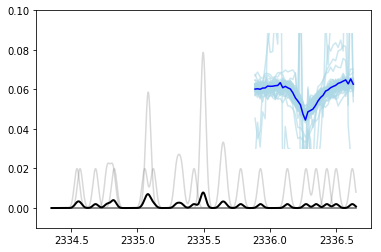

In [118]:
plt.figure(figsize=(6, 4))
trials_viewer.plot_psth(0)
plt.ylim(-.01, 0.1)

plt.axes([.62, .4, .25, .4])
wfs = trials_viewer.waveforms(unit=unit)[0]
plt.plot(wfs[:, 0, :].T, color="lightblue", alpha=0.6)
plt.plot(np.mean(wfs[:, 0, :], axis=0), color="blue")
plt.ylim(-400, 400)
plt.axis("off")
plt.show()


### Viewing psth of all units in response to stimuli

Can iterate over all the stimuli in the session, and group responses by stimulus and unit

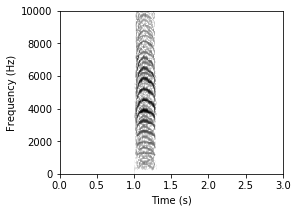

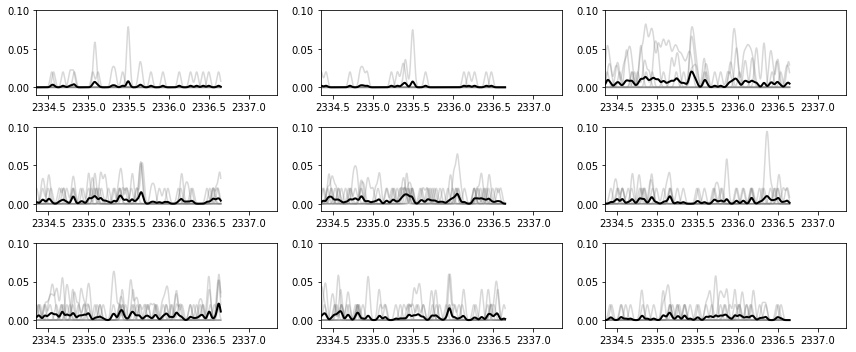

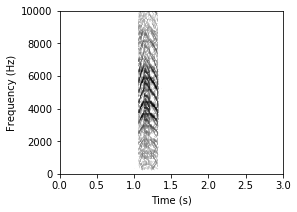

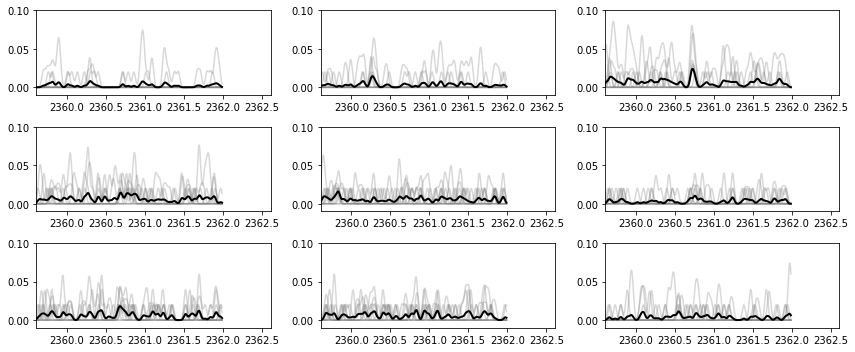

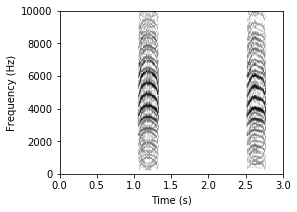

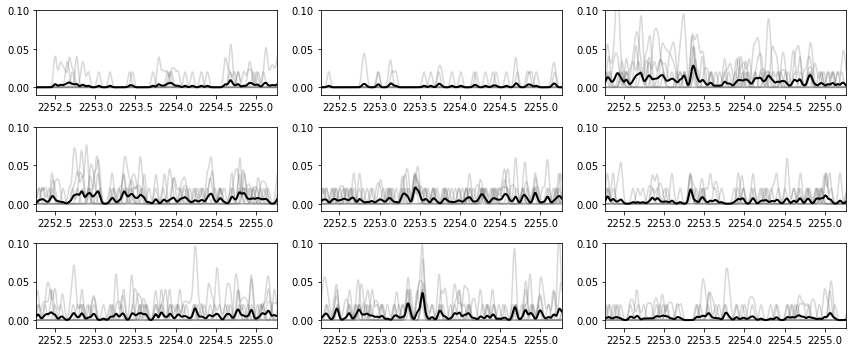

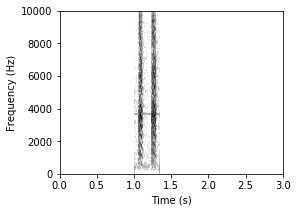

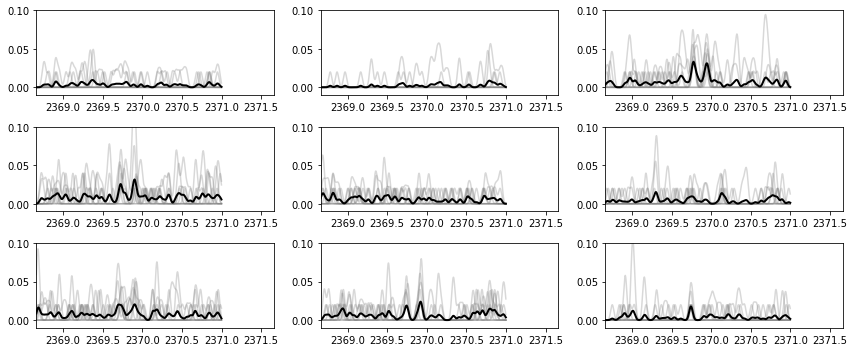

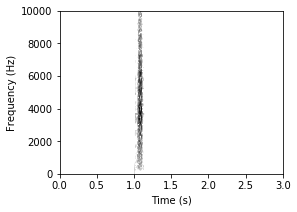

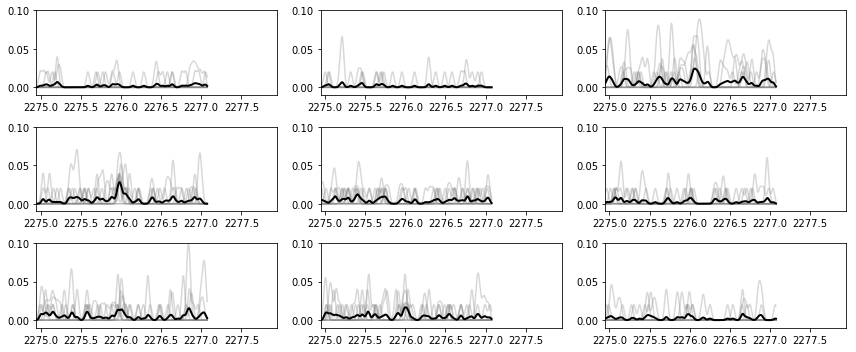

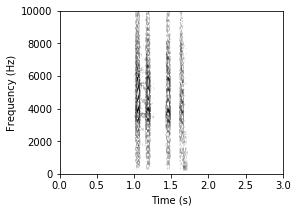

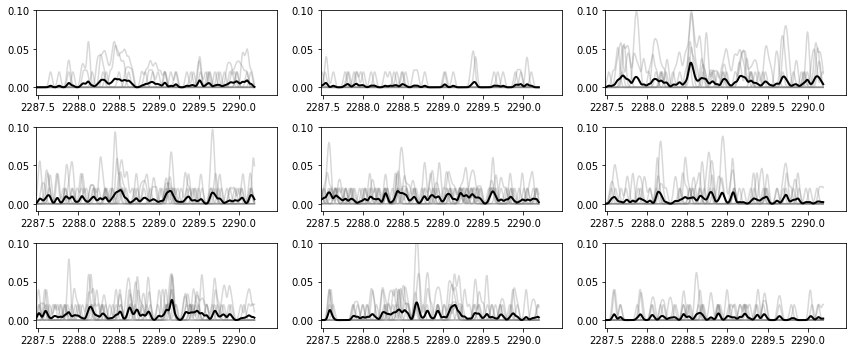

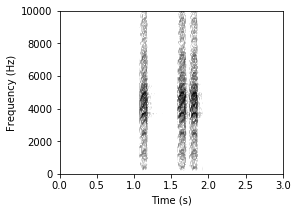

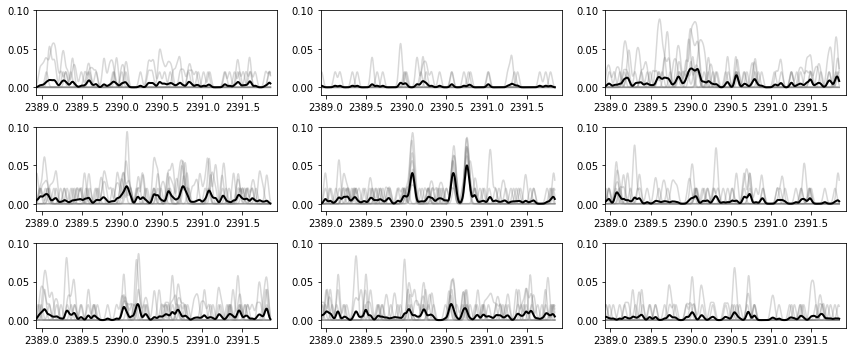

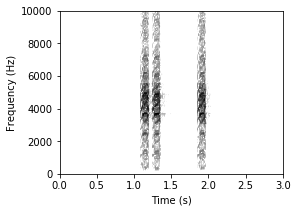

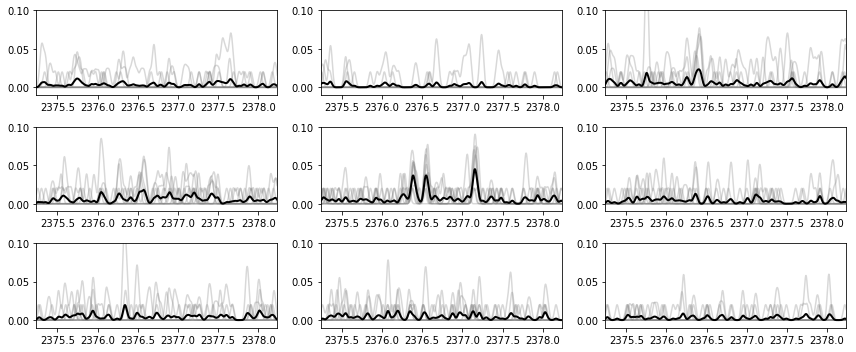

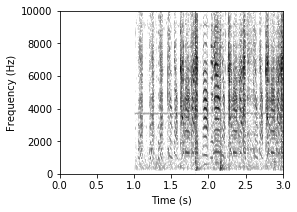

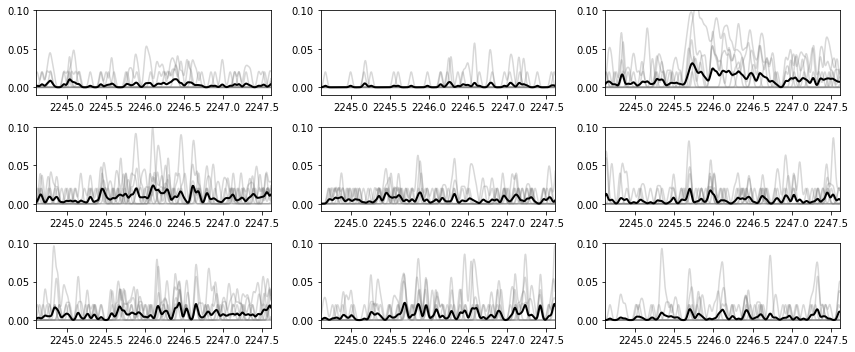

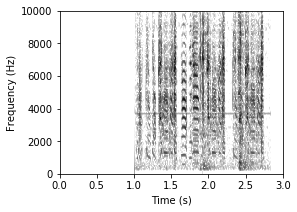

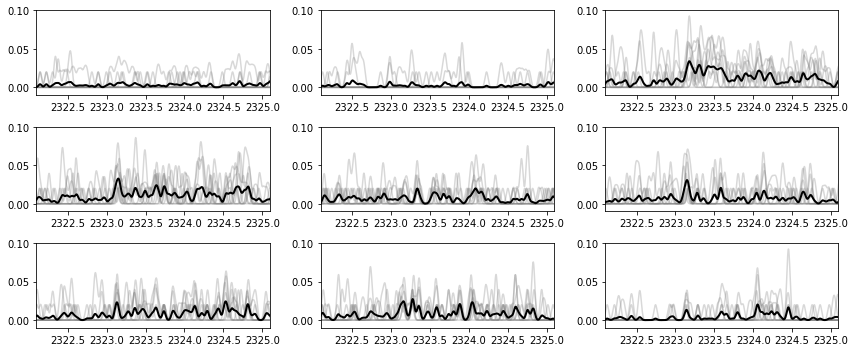

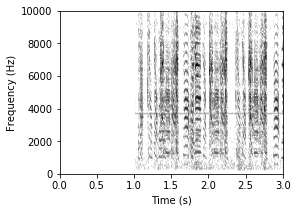

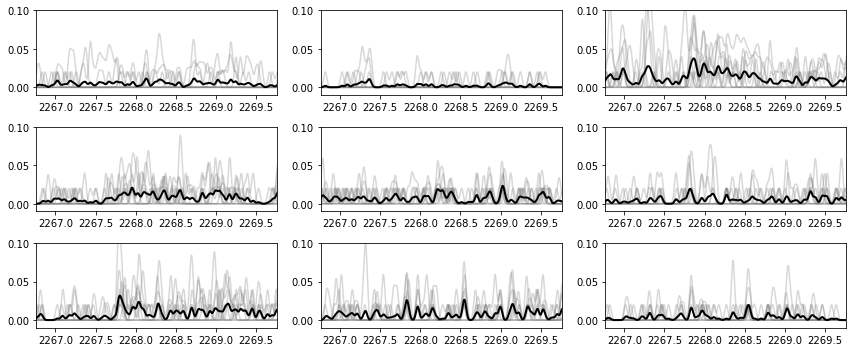

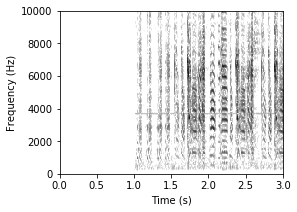

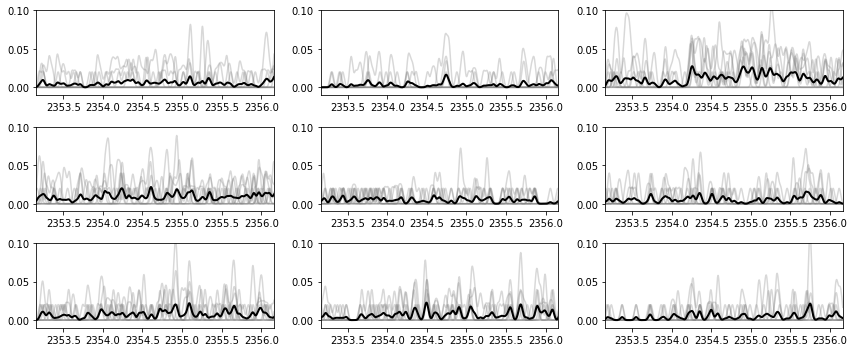

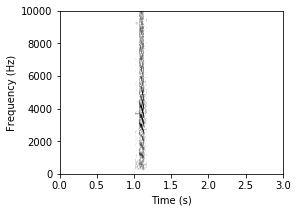

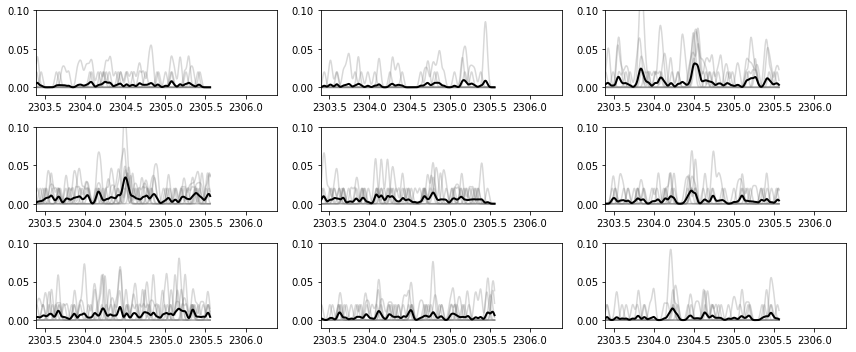

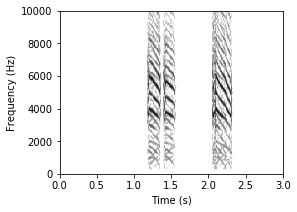

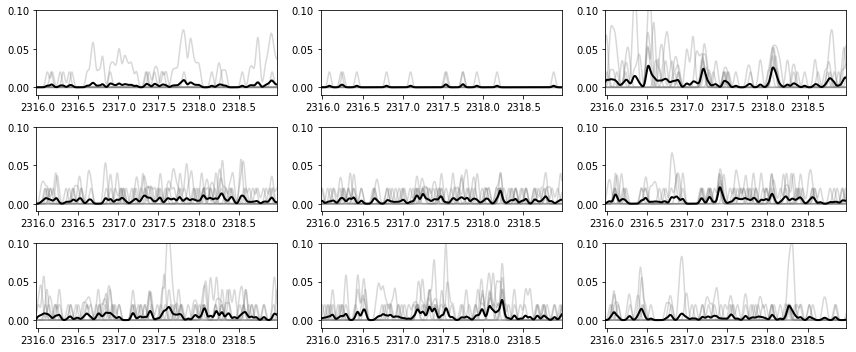

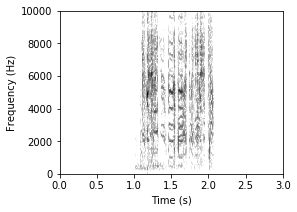

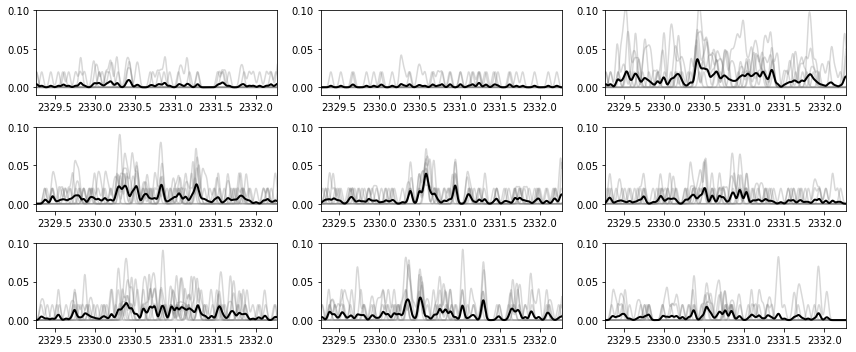

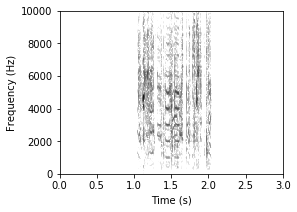

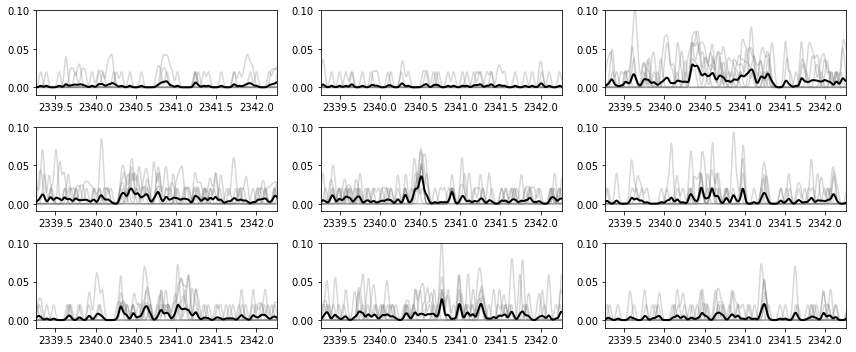

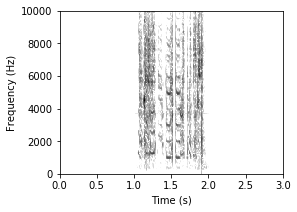

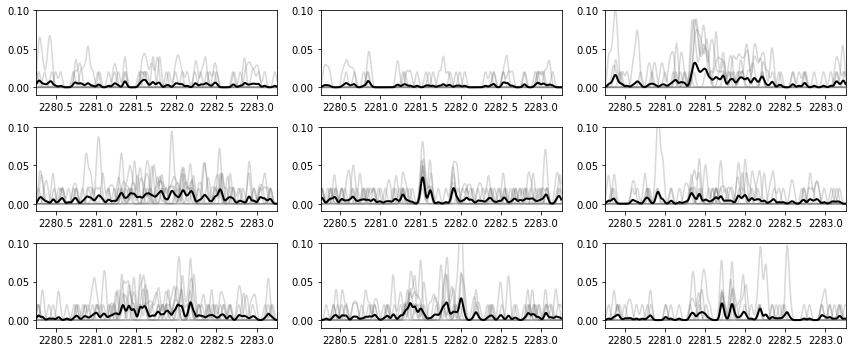

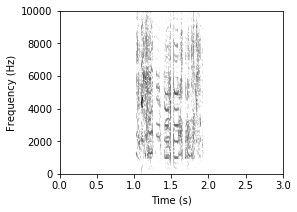

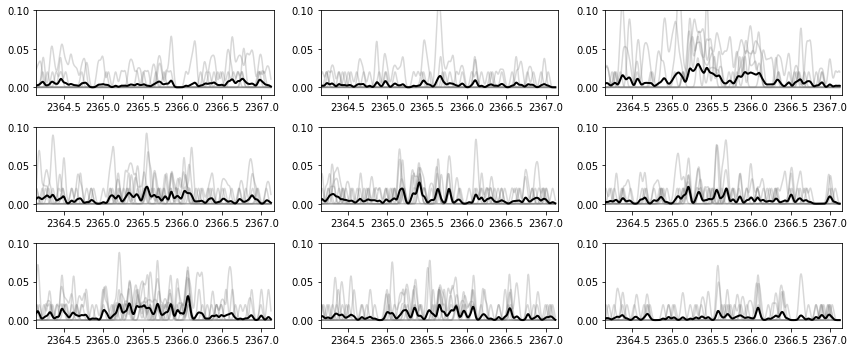

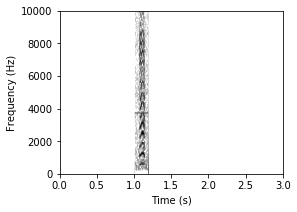

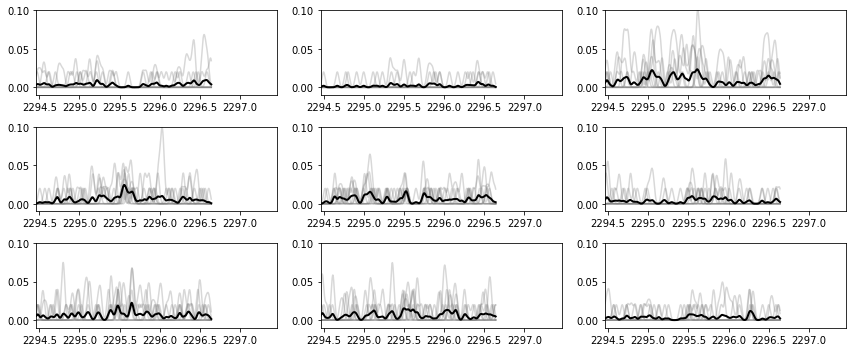

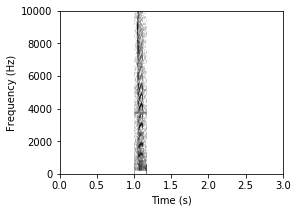

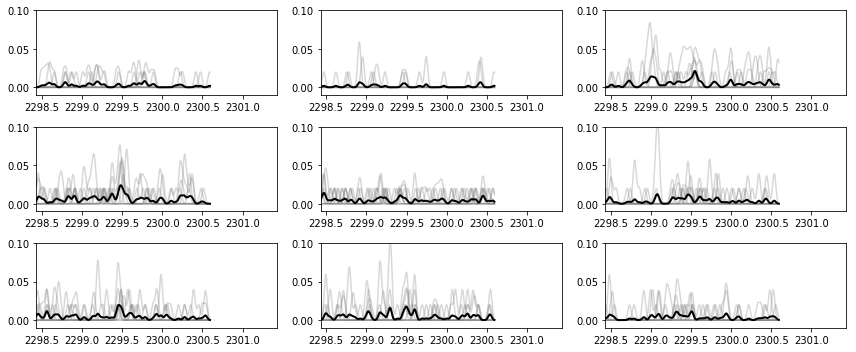

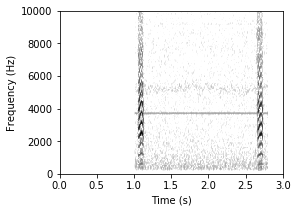

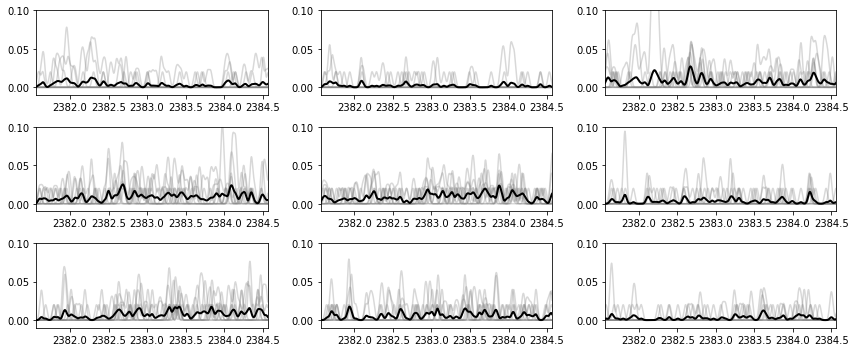

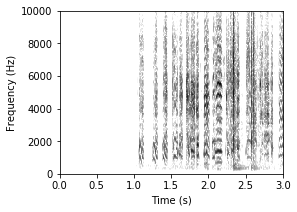

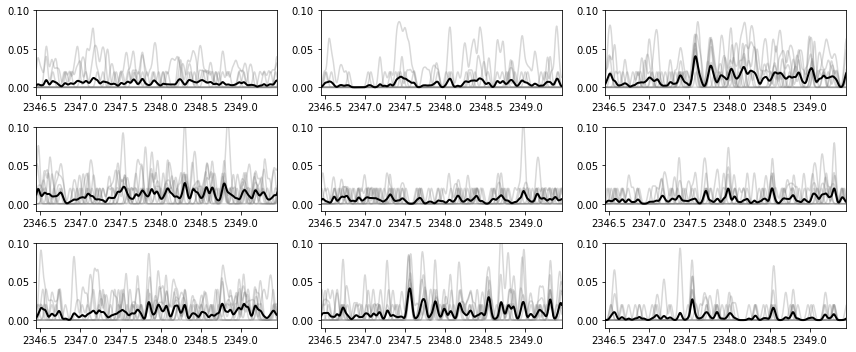

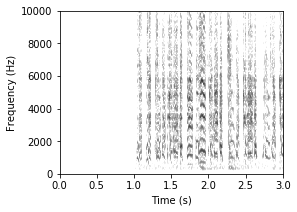

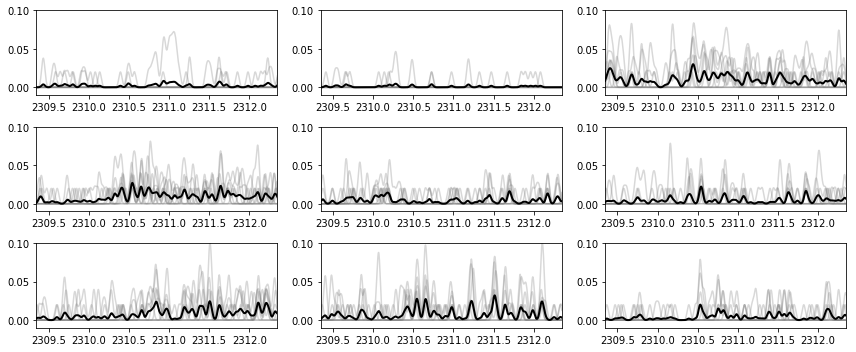

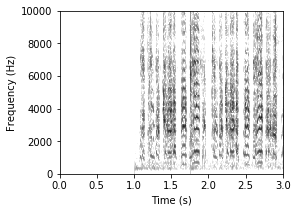

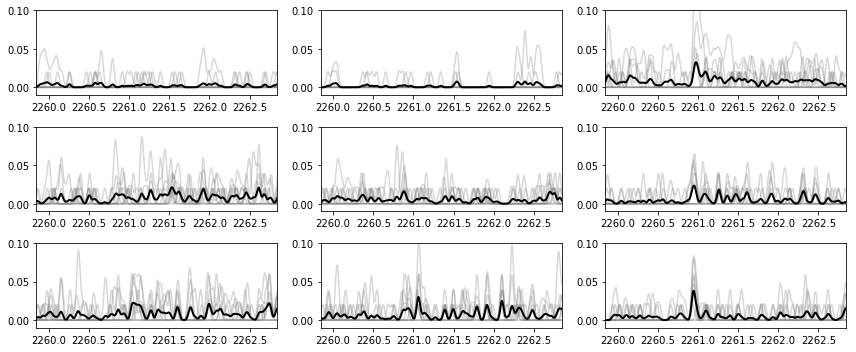

In [176]:
for stim_id in pbacks.stim_ids:
    trials_viewer = pbacks.get_playback_responses(stim_id)
    seg_viewer = trials_viewer.segment_viewers[0]
    
    # TODO: view spectrogram of playback wav file too
    fig, ax = plt.subplots(figsize=(4, 3))
    seg_viewer.plot_spectrogram(ax=ax)
    ax.set_xlim(0, 3.0)
    plt.show()

    plt.figure(figsize=(12, 5))
    for unit in trials_viewer.units:
        plt.subplot(3, 3, unit + 1)
        trials_viewer.plot_psth(unit)
        # plt.axis("off")
        plt.xlim(trials_viewer.t_arr()[0], trials_viewer.t_arr()[0] + 3.0)
        plt.ylim(-.01, 0.1)

    plt.tight_layout()
    plt.show()